In [65]:
import sys

print(sys.version)
print(sys.executable)

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
C:\Users\sapko\OneDrive - Université de Lausanne\Bureau\data science and machine learning\lazy_librarian\.venv_fixed\Scripts\python.exe


In [66]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# Folder containing this notebook and the three CSV files.
# In PyCharm, run the notebook with its working directory set to this folder.
DATA_FOLDER = os.getcwd()
print("Working directory:", DATA_FOLDER)
print("Files:", os.listdir(DATA_FOLDER))

Working directory: C:\Users\sapko\OneDrive - Université de Lausanne\Bureau\data science and machine learning\lazy_librarian
Files: ['.idea', '.venv', '.venv312', '.venv_fixed', '.venv_new', 'interactions_train.csv', 'items.csv', 'Lazy_Librarian_PyCharm_Ready.ipynb', 'sample_submission.csv', 'submission.csv', 'submission_normalized_item_item.csv']


In [67]:
# Load three CSV files from the local project folder.
# The competition attachment may be named interactions_train.csv or interactions.csv.
interaction_filename = "interactions_train.csv"
if not os.path.exists(os.path.join(DATA_FOLDER, interaction_filename)):
    interaction_filename = "interactions.csv"

interactions = pd.read_csv(os.path.join(DATA_FOLDER, interaction_filename))
items = pd.read_csv(os.path.join(DATA_FOLDER, "items.csv"))
submission = pd.read_csv(os.path.join(DATA_FOLDER, "sample_submission.csv"))

print("Interactions:", interactions.shape)
print("Items:", items.shape)
print("Submission users:", submission.shape)
display(interactions.head())
display(items.head())
display(submission.head())

Interactions: (87047, 3)
Items: (15291, 6)
Submission users: (7838, 2)


,u,i,t
0,4456,8581,1.687541e+09
1,142,1964,1.679585e+09
2,362,3705,1.706872e+09
3,1809,11317,1.673533e+09
4,4384,1323,1.681402e+09


,Title,Author,ISBN Valid,Publisher,Subjects,i
0,Classification décimale universelle : édition ...,NaN,9782871303336; 2871303339,Ed du CEFAL,Classification décimale universelle; Indexatio...,0
1,Les interactions dans l'enseignement des langu...,"Cicurel, Francine, 1947-",9782278058327; 2278058320,Didier,didactique--langue étrangère - enseignement; d...,1
2,Histoire de vie et recherche biographique : pe...,NaN,2343190194; 9782343190198,L'Harmattan,Histoires de vie en sociologie; Sciences socia...,2
3,Ce livre devrait me permettre de résoudre le c...,"Mazas, Sylvain, 1980-",9782365350020; 236535002X; 9782365350488; 2365...,Vraoum!,Moyen-Orient; Bandes dessinées autobiographiqu...,3
4,Les années glorieuses : roman /,"Lemaitre, Pierre, 1951-",9782702180815; 2702180817; 9782702183618; 2702...,Calmann-Lévy,France--1945-1975; Roman historique; Roman fra...,4


,user_id,recommendation
0,0,3758 11248 9088 9895 5101 6074 9295 14050 1096...
1,1,3263 726 1589 14911 6432 10897 6484 7961 8249 ...
2,2,13508 9848 12244 2742 11120 2893 2461 5439 116...
3,3,2821 10734 6357 5934 2085 12608 12539 10551 10...
4,4,12425 219 11602 1487 14178 489 13888 2110 4413...


## Exploratory data analysis (from your original notebook)

In [68]:
print("Number of unique users: ", interactions["u"].nunique())
print("Number of unique books borrowed", interactions["i"].nunique())

Number of unique users:  7838
Number of unique books borrowed 15109


In [69]:
print("missing values in interaction:")
print(interactions.isnull().sum())

print("\n missing values in items: ")
print(items.isnull().sum())

missing values in interaction:
u    0
i    0
t    0
dtype: int64

 missing values in items: 
Title            0
Author        2653
ISBN Valid     723
Publisher       25
Subjects      2223
i                0
dtype: int64


count    7838.000000
mean       11.105767
std        16.441875
min         3.000000
25%         3.000000
50%         6.000000
75%        11.000000
max       385.000000
dtype: float64


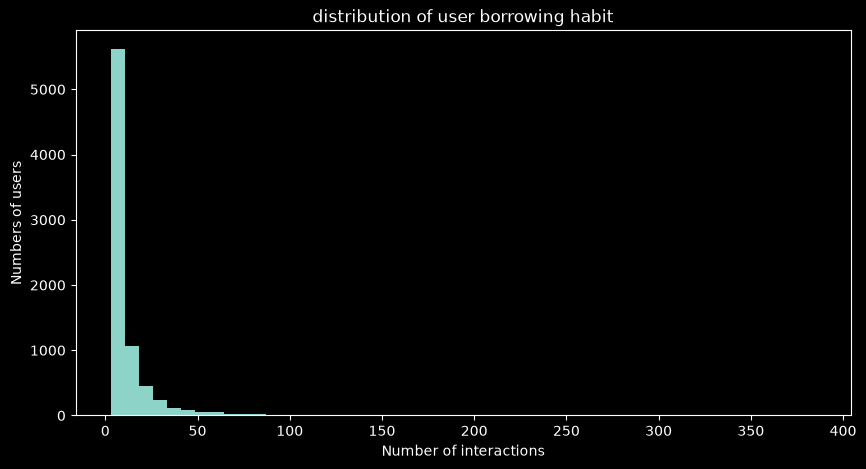

In [70]:
import matplotlib.pyplot as plt

#to count the borrowing interactions per user
user_habit = interactions.groupby("u").size()

print(user_habit.describe())

plt.figure(figsize= (10,5))
plt.hist(user_habit, bins=50)

plt.xlabel("Number of interactions")
plt.ylabel("Numbers of users")
plt.title("distribution of user borrowing habit")

plt.show()

count    15109.000000
mean         5.761268
std          9.004874
min          1.000000
25%          3.000000
50%          4.000000
75%          6.000000
max        380.000000
dtype: float64


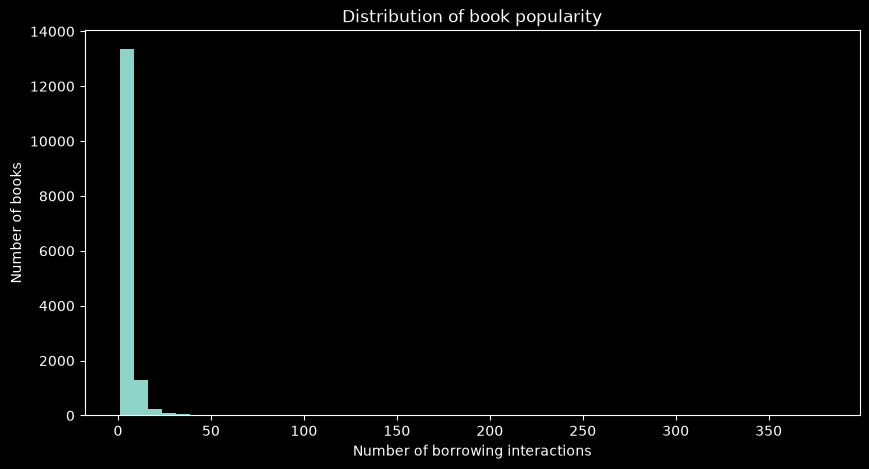

In [71]:
#find which book is popular
book_popularity = interactions.groupby("i").size()

print(book_popularity.describe())

plt.figure(figsize=(10,5))
plt.hist(book_popularity, bins=50)

plt.xlabel("Number of borrowing interactions")
plt.ylabel("Number of books")
plt.title("Distribution of book popularity")

plt.show()

In [72]:
n_users =interactions["u"].nunique()
n_items = items["i"].nunique()

#count unique user-book interactions
n_interactions = interactions[["u", "i"]].drop_duplicates().shape[0]

sparsity = 1- (n_interactions / (n_users * n_items))

print(f"Dataset sparsity: {sparsity:.4%}")

Dataset sparsity: 99.9466%


**Sparsity:** a high percentage means that most user-book combinations have no recorded borrowing interaction. This makes collaborative filtering harder.

## Local validation — hold out the latest distinct book per eligible user

In [73]:
# Keep the latest interaction for each (user, book) pair.
unique_interactions = (
    interactions.sort_values("t")
    .drop_duplicates(["u", "i"], keep="last")
)

# Each validation user needs at least two distinct books.
counts = unique_interactions.groupby("u")["i"].transform("size")
validation = (
    unique_interactions[counts >= 2]
    .sort_values("t")
    .groupby("u")
    .tail(1)[["u", "i"]]
    .copy()
)

# Remove ALL events for each held-out user-book pair from training.
train = interactions.merge(
    validation.rename(columns={"i": "heldout_i"}), on="u", how="left"
)
train = train[
    train["heldout_i"].isna() | (train["i"] != train["heldout_i"])
].drop(columns="heldout_i")

print("Training interactions:", len(train))
print("Validation users:", len(validation))
print("Overlap of held-out pairs:", len(train[["u", "i"]].merge(validation, on=["u", "i"])))

Training interactions: 74979
Validation users: 7521
Overlap of held-out pairs: 0


## Item-item collaborative filtering (cosine similarity)

In [74]:
# Same binary user-item interaction concept as the recommender systems lab.
# Sparse storage is used because most matrix entries are zero.
user_ids = np.sort(interactions["u"].unique())
item_ids = np.sort(items["i"].unique())

user_to_index = {u: idx for idx, u in enumerate(user_ids)}
item_to_index = {i: idx for idx, i in enumerate(item_ids)}

def create_data_matrix(data):
    unique_data = data[["u", "i"]].drop_duplicates()
    return csr_matrix(
        (
            np.ones(len(unique_data), dtype=np.float32),
            (
                unique_data["u"].map(user_to_index).values,
                unique_data["i"].map(item_to_index).values
            )
        ),
        shape=(len(user_ids), len(item_ids)),
        dtype=np.float32
    )

train_data_matrix = create_data_matrix(train)
print("User-item matrix shape:", train_data_matrix.shape)

User-item matrix shape: (7838, 15291)


In [75]:
# Cosine similarity between books based on borrowing histories.
item_similarity = cosine_similarity(train_data_matrix.T, dense_output=False)
item_similarity.setdiag(0)
item_similarity.eliminate_zeros()

# Score candidates using the summed item similarities (original model).
item_prediction = train_data_matrix.dot(item_similarity)
print("Item similarity shape:", item_similarity.shape)
print("Predictions shape:", item_prediction.shape)

Item similarity shape: (15291, 15291)
Predictions shape: (7838, 15291)


In [76]:
def recommend_books(user_id, k=10):
    user_idx = user_to_index[user_id]

    scores = item_prediction.getrow(user_idx).toarray().flatten()

    # Do not recommend books already borrowed by this user.
    borrowed = train_data_matrix.getrow(user_idx).indices
    scores[borrowed] = -np.inf

    top_k = np.argsort(scores)[::-1][:k]
    return item_ids[top_k].tolist()

print("Example user:", user_ids[0])
print("Top-10 recommended book IDs:", recommend_books(user_ids[0]))

Example user: 0
Top-10 recommended book IDs: [9021, 9012, 1274, 8506, 9006, 9009, 9004, 1432, 9008, 1182]


## Local MAP@10 — score *before* the final submission

In [77]:
# Because we hold out one distinct book per validation user,
# AP@10 for that user is 1/rank if it is recommended, otherwise 0.
def calculate_map10(validation):
    user_scores = []

    for user_id, true_book in validation[["u", "i"]].itertuples(index=False, name=None):
        recommendations = recommend_books(user_id, k=10)
        if true_book in recommendations:
            rank = recommendations.index(true_book) + 1
            user_scores.append(1 / rank)
        else:
            user_scores.append(0)

    return np.mean(user_scores)

local_score = calculate_map10(validation)
print(f"Local validation MAP@10: {local_score:.5f}")
print("This is NOT the official Kaggle leaderboard score.")

Local validation MAP@10: 0.03928
This is NOT the official Kaggle leaderboard score.


## Retrain using all interactions for the Kaggle submission

In [78]:
# The validation split is only for local testing.
# Rebuild the binary matrix using the complete interaction history.
train_data_matrix = create_data_matrix(interactions)

item_similarity = cosine_similarity(train_data_matrix.T, dense_output=False)
item_similarity.setdiag(0)
item_similarity.eliminate_zeros()

item_prediction = train_data_matrix.dot(item_similarity)
print("Model rebuilt using all interactions.")

Model rebuilt using all interactions.


## Generate and save `submission.csv` in your PyCharm project folder

In [79]:
# Each submission row requires 10 space-separated book IDs.
submission["recommendation"] = submission["user_id"].apply(
    lambda u: " ".join(map(str, recommend_books(u, k=10)))
)

# Basic validity checks
assert submission["recommendation"].apply(lambda x: len(x.split()) == 10).all()
assert submission["recommendation"].apply(lambda x: len(set(x.split())) == 10).all()
assert submission["user_id"].is_unique
assert submission["recommendation"].apply(
    lambda x: all(int(book) in item_to_index for book in x.split())
).all()

output_file = os.path.join(DATA_FOLDER, "submission.csv")
submission.to_csv(output_file, index=False)

print("Submission saved to:", output_file)
print("Total users:", len(submission))
display(submission.head())

Submission saved to: C:\Users\sapko\OneDrive - Université de Lausanne\Bureau\data science and machine learning\lazy_librarian\submission.csv
Total users: 7838


,user_id,recommendation
0,0,9006 9012 1274 8506 9021 9009 9004 1432 9016 9008
1,1,6336 15066 6003 9603 7021 2641 2719 9546 15067...
2,2,2549 9929 10013 9909 2513 2554 2487 2514 2120 ...
3,3,3325 7331 3356 3281 3324 2477 6200 6199 2476 3359
4,4,3124 3127 3120 3123 6532 3126 2225 1547 6313 1514


#####take 2: normalized item-item filtering

In [80]:
# Model 2: Popularity-adjusted item-item CF

book_popularity = np.asarray(train_data_matrix.sum(axis=0)).ravel()

popularity_weight = 1 / np.sqrt(
    np.maximum(book_popularity, 1)
)

normalized_similarity = item_similarity.multiply(
    popularity_weight.reshape(1, -1)
).tocsr()

In [81]:
# Calculate recommendation scores using normalized similarities
normalized_prediction = train_data_matrix.dot(normalized_similarity)

print("Normalized prediction shape:", normalized_prediction.shape)

Normalized prediction shape: (7838, 15291)


In [82]:
def recommend_books_normalized(user_id, k=10):

    user_idx = user_to_index[user_id]

    # Get normalized scores for this user
    scores = normalized_prediction.getrow(user_idx).toarray().flatten()

    # Exclude books already borrowed
    borrowed = train_data_matrix.getrow(user_idx).indices
    scores[borrowed] = -np.inf

    # Select the top 10 books
    top_k = np.argsort(scores)[::-1][:k]

    return item_ids[top_k].tolist()

In [83]:
test_user = user_ids[0]

print("User:", test_user)

print("Original recommendations:")
print(recommend_books(test_user, k=10))

print("\nNormalized recommendations:")
print(recommend_books_normalized(test_user, k=10))

User: 0
Original recommendations:
[9006, 9012, 1274, 8506, 9021, 9009, 9004, 1432, 9016, 9008]

Normalized recommendations:
[9021, 8506, 9006, 1274, 9012, 9009, 9004, 13228, 4977, 9016]


In [84]:
submission_normalized = submission.copy()

submission_normalized["recommendation"] = (
    submission_normalized["user_id"].apply(
        lambda u: " ".join(
            map(str, recommend_books_normalized(u, k=10))
        )
    )
)

# Validate submission format
assert submission_normalized["recommendation"].apply(
    lambda x: len(x.split()) == 10
).all()

assert submission_normalized["recommendation"].apply(
    lambda x: len(set(x.split())) == 10
).all()

# Save new submission
output_file_normalized = os.path.join(
    DATA_FOLDER,
    "submission_normalized_item_item.csv"
)

submission_normalized.to_csv(
    output_file_normalized,
    index=False
)

print("Saved to:", output_file_normalized)

display(submission_normalized.head())

Saved to: C:\Users\sapko\OneDrive - Université de Lausanne\Bureau\data science and machine learning\lazy_librarian\submission_normalized_item_item.csv


,user_id,recommendation
0,0,9021 8506 9006 1274 9012 9009 9004 13228 4977 ...
1,1,4947 15066 6003 13704 15249 15068 10226 4248 3...
2,2,2524 6917 9929 9035 10806 9684 2120 9899 14553...
3,3,3324 3281 7331 3349 7329 3325 8957 5996 6199 3334
4,4,6532 3123 3127 3521 12796 12795 12794 12798 12...


#######model 3: User-User collaborative filtering, similar borrowing histories.

In [85]:
# Create the training matrix for local validation
R_val = create_data_matrix(train)

print("Training matrix shape:", R_val.shape)


# Calculate cosine similarity between users
user_similarity = cosine_similarity(
    R_val,
    dense_output=False
)

# Exclude self-similarity
user_similarity.setdiag(0)
user_similarity.eliminate_zeros()

print("User similarity shape:", user_similarity.shape)

Training matrix shape: (7838, 15291)
User similarity shape: (7838, 7838)


In [87]:
# Retrain user-user CF using all interactions
R_full = create_data_matrix(interactions)

user_similarity_full = cosine_similarity(
    R_full,
    dense_output=False
)

user_similarity_full.setdiag(0)
user_similarity_full.eliminate_zeros()

print("Full model ready!")

Full model ready!


In [88]:
print("R_full exists:", "R_full" in globals())
print("user_similarity_full exists:", "user_similarity_full" in globals())

R_full exists: True
user_similarity_full exists: True


In [92]:
def recommend_user_user_full(user_id, k=10, n_neighbors=30):

    user_idx = user_to_index[user_id]

    similarities = user_similarity_full.getrow(user_idx)

    neighbor_indices = similarities.indices
    neighbor_scores = similarities.data

    top_neighbors = np.argsort(
        neighbor_scores
    )[-n_neighbors:]

    neighbor_indices = neighbor_indices[top_neighbors]
    neighbor_scores = neighbor_scores[top_neighbors]

    scores = np.asarray(
        neighbor_scores @ R_full[neighbor_indices]
    ).ravel()

    borrowed = R_full.getrow(user_idx).indices
    scores[borrowed] = -np.inf

    top_k = np.argsort(scores)[::-1][:k]

    return item_ids[top_k].tolist()


# Verify the function is now defined
print("Function exists:", "recommend_user_user_full" in globals())

Function exists: True


In [93]:
submission_user_user = submission.copy()

submission_user_user["recommendation"] = (
    submission_user_user["user_id"].apply(
        lambda u: " ".join(
            map(str, recommend_user_user_full(u, k=10))
        )
    )
)

# Check submission format
assert submission_user_user["recommendation"].apply(
    lambda x: len(x.split()) == 10
).all()

assert submission_user_user["recommendation"].apply(
    lambda x: len(set(x.split())) == 10
).all()

# Save to a separate CSV file
output_file = os.path.join(
    DATA_FOLDER,
    "submission_user_user.csv"
)

submission_user_user.to_csv(
    output_file,
    index=False
)

print("Submission saved to:", output_file)
display(submission_user_user.head())

Submission saved to: C:\Users\sapko\OneDrive - Université de Lausanne\Bureau\data science and machine learning\lazy_librarian\submission_user_user.csv


,user_id,recommendation
0,0,9759 13307 8096 2130 9007 759 611 8404 8195 12049
1,1,323 1573 3546 3543 27 1239 128 424 3971 1367
2,2,8999 14824 7129 1988 2031 11440 11444 3237 124...
3,3,10373 10372 10370 10371 2474 4726 6575 1397 58...
4,4,3124 3126 11366 14703 3128 1547 2945 3120 3123...


#####model 3.1: to test with different neighbors

In [95]:
# Test different numbers of neighbors
neighbor_values = [5, 10, 20, 30, 50, 75, 100, 150, 200, 250, 300, 400, 500, 750, 1000]

results = []

for n in neighbor_values:

    user_scores = []

    for user_id, true_book in validation[["u", "i"]].itertuples(
        index=False, name=None
    ):

        recommendations = recommend_user_user(
            user_id,
            k=10,
            n_neighbors=n
        )

        if true_book in recommendations:
            rank = recommendations.index(true_book) + 1
            user_scores.append(1 / rank)
        else:
            user_scores.append(0)

    map10 = np.mean(user_scores)

    results.append({
        "Neighbors": n,
        "MAP@10": map10
    })

    print(f"Neighbors: {n:3d} | MAP@10: {map10:.5f}")

results_df = pd.DataFrame(results)

display(results_df)

Neighbors:   5 | MAP@10: 0.03220
Neighbors:  10 | MAP@10: 0.04097
Neighbors:  20 | MAP@10: 0.04563
Neighbors:  30 | MAP@10: 0.05074
Neighbors:  50 | MAP@10: 0.05233
Neighbors:  75 | MAP@10: 0.05336
Neighbors: 100 | MAP@10: 0.05371
Neighbors: 150 | MAP@10: 0.05396
Neighbors: 200 | MAP@10: 0.05375
Neighbors: 250 | MAP@10: 0.05377
Neighbors: 300 | MAP@10: 0.05376
Neighbors: 400 | MAP@10: 0.05376


,Neighbors,MAP@10
0,5,0.032197
1,10,0.040968
2,20,0.045628
3,30,0.050741
4,50,0.052335
5,75,0.053364
6,100,0.053711
7,150,0.053957
8,200,0.053753
9,250,0.053767


In [96]:
submission_150 = submission.copy()

submission_150["recommendation"] = (
    submission_150["user_id"].apply(
        lambda u: " ".join(
            map(str, recommend_user_user_full(
                u,
                k=10,
                n_neighbors=150
            ))
        )
    )
)

output_file = os.path.join(
    DATA_FOLDER,
    "submission_user_user_150.csv"
)

submission_150.to_csv(output_file, index=False)

print("Saved:", output_file)
display(submission_150.head())

Saved: C:\Users\sapko\OneDrive - Université de Lausanne\Bureau\data science and machine learning\lazy_librarian\submission_user_user_150.csv


,user_id,recommendation
0,0,611 9759 8096 13307 466 794 2141 46 3811 9088
1,1,323 1573 5097 2130 3543 3546 3222 128 27 1239
2,2,8999 2556 2574 2130 2489 3055 2549 2490 2580 2026
3,3,466 10373 686 10372 873 1397 4635 794 1161 4987
4,4,2225 3124 424 3126 3120 3127 964 4712 476 1547


##### next model: hybrid: item-item, user-user

In [98]:
# Use validation training data only
R_val = create_data_matrix(train)

# Item-item CF predictions
item_sim_val = cosine_similarity(
    R_val.T,
    dense_output=False
)

item_sim_val.setdiag(0)
item_sim_val.eliminate_zeros()

item_scores_val = R_val @ item_sim_val

# User-user CF predictions (150 neighbors)
user_sim_val = cosine_similarity(
    R_val,
    dense_output=False
)

user_sim_val.setdiag(0)
user_sim_val.eliminate_zeros()

In [99]:
def recommend_hybrid(user_id, alpha=0.5, k=10, n_neighbors=150):

    user_idx = user_to_index[user_id]

    # Item-item scores
    item_scores = item_scores_val.getrow(
        user_idx
    ).toarray().ravel()

    # Find nearest users
    similarities = user_sim_val.getrow(user_idx)

    neighbor_indices = similarities.indices
    neighbor_scores = similarities.data

    top_neighbors = np.argsort(
        neighbor_scores
    )[-n_neighbors:]

    neighbor_indices = neighbor_indices[top_neighbors]
    neighbor_scores = neighbor_scores[top_neighbors]

    # User-user scores
    user_scores = np.asarray(
        neighbor_scores @ R_val[neighbor_indices]
    ).ravel()

    # Normalize scores to [0, 1]
    if item_scores.max() > 0:
        item_scores = item_scores / item_scores.max()

    if user_scores.max() > 0:
        user_scores = user_scores / user_scores.max()

    # Combine the two models
    hybrid_scores = (
        alpha * user_scores
        + (1 - alpha) * item_scores
    )

    # Exclude previously borrowed books
    borrowed = R_val.getrow(user_idx).indices
    hybrid_scores[borrowed] = -np.inf

    top_k = np.argsort(hybrid_scores)[::-1][:k]

    return item_ids[top_k].tolist()

In [100]:
alpha_values = [0, 0.25, 0.5, 0.75, 1.0]

hybrid_results = []

for alpha in alpha_values:

    user_scores = []

    for user_id, true_book in validation[["u", "i"]].itertuples(
        index=False, name=None
    ):

        recommendations = recommend_hybrid(
            user_id,
            alpha=alpha,
            k=10,
            n_neighbors=150
        )

        if true_book in recommendations:
            rank = recommendations.index(true_book) + 1
            user_scores.append(1 / rank)
        else:
            user_scores.append(0)

    map10 = np.mean(user_scores)

    hybrid_results.append({
        "Alpha": alpha,
        "MAP@10": map10
    })

    print(f"Alpha: {alpha:.2f} | MAP@10: {map10:.5f}")

hybrid_results_df = pd.DataFrame(hybrid_results)

display(hybrid_results_df)

Alpha: 0.00 | MAP@10: 0.03925
Alpha: 0.25 | MAP@10: 0.04498
Alpha: 0.50 | MAP@10: 0.04948
Alpha: 0.75 | MAP@10: 0.05365
Alpha: 1.00 | MAP@10: 0.05396


,Alpha,MAP@10
0,0.00,0.039250
1,0.25,0.044977
2,0.50,0.049482
3,0.75,0.053648
4,1.00,0.053957


### can't improve with hybrid with item-item since alpha=1 for best


####model 5: TF-IDF feature: look for similar content

In [101]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Combine book metadata
items_content = items.copy()

for col in ["Title", "Author", "Subjects"]:
    items_content[col] = items_content[col].fillna("").astype(str)

items_content["content"] = (
    items_content["Title"] + " " +
    items_content["Author"] + " " +
    items_content["Subjects"]
)

# Keep the same book order as your interaction matrix
items_content = (
    items_content.set_index("i")
    .reindex(item_ids)
    .fillna("")
)

# Create TF-IDF matrix
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000
)

tfidf_matrix = tfidf.fit_transform(items_content["content"])

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (15291, 10000)


In [102]:
# User profiles from training interactions
user_profiles = R_val @ tfidf_matrix

# Normalize user profiles
from sklearn.preprocessing import normalize

user_profiles = normalize(user_profiles)

def recommend_content(user_id, k=10):
    user_idx = user_to_index[user_id]

    # Compare user profile with all books
    scores = (
        user_profiles.getrow(user_idx) @ tfidf_matrix.T
    ).toarray().ravel()

    # Exclude previously borrowed books
    borrowed = R_val.getrow(user_idx).indices
    scores[borrowed] = -np.inf

    top_k = np.argsort(scores)[::-1][:k]

    return item_ids[top_k].tolist()

In [103]:
content_scores = []

for user_id, true_book in validation[["u", "i"]].itertuples(
    index=False, name=None
):
    recommendations = recommend_content(user_id, k=10)

    if true_book in recommendations:
        rank = recommendations.index(true_book) + 1
        content_scores.append(1 / rank)
    else:
        content_scores.append(0)

content_map10 = np.mean(content_scores)

print(f"Content-based TF-IDF MAP@10: {content_map10:.5f}")

Content-based TF-IDF MAP@10: 0.05141


In [104]:
# Rebuild user profiles using all interactions
R_full = create_data_matrix(interactions)

user_profiles_full = normalize(R_full @ tfidf_matrix)

def recommend_content_full(user_id, k=10):
    user_idx = user_to_index[user_id]

    scores = (
        user_profiles_full.getrow(user_idx) @ tfidf_matrix.T
    ).toarray().ravel()

    borrowed = R_full.getrow(user_idx).indices
    scores[borrowed] = -np.inf

    top_k = np.argsort(scores)[::-1][:k]

    return item_ids[top_k].tolist()


# Generate submission
submission_content = submission.copy()

submission_content["recommendation"] = (
    submission_content["user_id"].apply(
        lambda u: " ".join(
            map(str, recommend_content_full(u, k=10))
        )
    )
)

submission_content.to_csv(
    "submission_content.csv",
    index=False
)

display(submission_content.head())

,user_id,recommendation
0,0,4512 13261 8404 1583 9759 13903 3765 10710 533...
1,1,8872 4635 11876 6892 11481 11379 11376 3818 25...
2,2,112 15211 7159 8587 8050 7111 15112 4432 15067...
3,3,5549 3596 5030 5928 1233 10920 5893 5154 1574 ...
4,4,1052 3752 5925 10710 248 544 5505 3765 4284 3291


####model 5: user-user with 150 neighbors

##recency-weighted user-user CF : treating recent interactions weight more than older interactions

In [105]:
print(interactions["t"].dtype)
print(interactions["t"].describe())
print(interactions[["u", "i", "t"]].head(10))

float64
count    8.704700e+04
mean     1.695743e+09
std      1.419829e+07
min      1.672664e+09
25%      1.683051e+09
50%      1.695917e+09
75%      1.707222e+09
max      1.728925e+09
Name: t, dtype: float64
      u      i             t
0  4456   8581  1.687541e+09
1   142   1964  1.679585e+09
2   362   3705  1.706872e+09
3  1809  11317  1.673533e+09
4  4384   1323  1.681402e+09
5  2369      1  1.695304e+09
6   259   3263  1.680104e+09
7  6239   1166  1.680263e+09
8  2744  12933  1.719325e+09
9  6597  14891  1.702570e+09


In [106]:
def create_weighted_matrix(data, decay=1.0):

    # Keep the latest interaction for each user-book pair
    unique_data = (
        data.sort_values("t")
        .drop_duplicates(["u", "i"], keep="last")
        .copy()
    )

    # Calculate how old each interaction is
    t_min = unique_data["t"].min()
    t_max = unique_data["t"].max()

    if t_max > t_min:
        age = (
            (t_max - unique_data["t"]) /
            (t_max - t_min)
        )
    else:
        age = np.zeros(len(unique_data))

    # Recent books receive larger weights
    weights = np.exp(-decay * age)

    weighted_matrix = csr_matrix(
        (
            weights.astype(np.float32),
            (
                unique_data["u"].map(user_to_index),
                unique_data["i"].map(item_to_index)
            )
        ),
        shape=(len(user_ids), len(item_ids)),
        dtype=np.float32
    )

    return weighted_matrix

In [107]:
def build_weighted_model(data, decay):

    R_weighted = create_weighted_matrix(data, decay)

    similarity = cosine_similarity(
        R_weighted,
        dense_output=False
    )

    similarity.setdiag(0)
    similarity.eliminate_zeros()

    return R_weighted, similarity

In [108]:
def recommend_weighted(
    user_id,
    R_weighted,
    similarity,
    k=10,
    n_neighbors=150
):

    user_idx = user_to_index[user_id]

    similarities = similarity.getrow(user_idx)

    neighbor_indices = similarities.indices
    neighbor_scores = similarities.data

    top_neighbors = np.argsort(
        neighbor_scores
    )[-n_neighbors:]

    neighbor_indices = neighbor_indices[top_neighbors]
    neighbor_scores = neighbor_scores[top_neighbors]

    scores = np.asarray(
        neighbor_scores @ R_weighted[neighbor_indices]
    ).ravel()

    # Exclude books already borrowed
    borrowed = R_weighted.getrow(user_idx).indices
    scores[borrowed] = -np.inf

    top_k = np.argsort(scores)[::-1][:k]

    return item_ids[top_k].tolist()

In [109]:
decay_values = [0, 0.5, 1, 2, 5]

weighted_results = []

for decay in decay_values:

    print(f"Testing decay = {decay}")

    R_weighted, similarity = build_weighted_model(
        train,
        decay
    )

    scores = []

    for user_id, true_book in validation[["u", "i"]].itertuples(
        index=False,
        name=None
    ):

        recommendations = recommend_weighted(
            user_id,
            R_weighted,
            similarity,
            k=10,
            n_neighbors=150
        )

        if true_book in recommendations:
            rank = recommendations.index(true_book) + 1
            scores.append(1 / rank)
        else:
            scores.append(0)

    map10 = np.mean(scores)

    weighted_results.append({
        "Decay": decay,
        "MAP@10": map10
    })

    print(f"MAP@10: {map10:.5f}\n")

weighted_results_df = pd.DataFrame(weighted_results)

display(weighted_results_df)

Testing decay = 0
MAP@10: 0.05396

Testing decay = 0.5
MAP@10: 0.05411

Testing decay = 1
MAP@10: 0.05305

Testing decay = 2
MAP@10: 0.04859

Testing decay = 5
MAP@10: 0.03823



,Decay,MAP@10
0,0.0,0.053957
1,0.5,0.054108
2,1.0,0.053046
3,2.0,0.048590
4,5.0,0.038229


In [110]:
best_decay = weighted_results_df.loc[
    weighted_results_df["MAP@10"].idxmax(),
    "Decay"
]

print("Best decay:", best_decay)

# Train using all interactions
R_weighted_full, similarity_full = build_weighted_model(
    interactions,
    best_decay
)

submission_weighted = submission.copy()

submission_weighted["recommendation"] = (
    submission_weighted["user_id"].apply(
        lambda u: " ".join(
            map(
                str,
                recommend_weighted(
                    u,
                    R_weighted_full,
                    similarity_full,
                    k=10,
                    n_neighbors=150
                )
            )
        )
    )
)

submission_weighted.to_csv(
    "submission_weighted.csv",
    index=False
)

display(submission_weighted.head())

Best decay: 0.5


,user_id,recommendation
0,0,611 9759 8096 13307 794 466 1880 9007 9088 759
1,1,323 1573 3543 128 27 3222 424 5097 3546 6336
2,2,8999 2574 2556 14824 2549 3055 2130 14166 1457...
3,3,466 10373 10372 794 686 873 611 1161 1397 10370
4,4,2225 3124 3126 424 3127 3120 476 3128 4712 11815


###TF-IDF weighting of borrowing patterns

In [113]:
from sklearn.preprocessing import normalize

# Use the decay value from your best Kaggle submission
best_decay = weighted_results_df.loc[
    weighted_results_df["MAP@10"].idxmax(),
    "Decay"
]

R_weighted_val = create_weighted_matrix(train, best_decay)

# Count users who borrowed each book
book_frequency = np.asarray(
    (R_weighted_val > 0).sum(axis=0)
).ravel()

# Calculate IDF weights
idf = np.log(
    (R_weighted_val.shape[0] + 1) /
    (book_frequency + 1)
) + 1

# Apply IDF weighting
R_idf_val = R_weighted_val.multiply(idf).tocsr()

# Calculate cosine similarity using IDF-weighted interactions
similarity_idf_val = cosine_similarity(
    R_idf_val,
    dense_output=False
)

similarity_idf_val.setdiag(0)
similarity_idf_val.eliminate_zeros()

In [114]:
idf_scores = []

for user_id, true_book in validation[["u", "i"]].itertuples(
    index=False,
    name=None
):
    recommendations = recommend_weighted(
        user_id,
        R_weighted_val,      # Original recency-weighted interactions
        similarity_idf_val,  # IDF-weighted user similarity
        k=10,
        n_neighbors=150
    )

    if true_book in recommendations:
        rank = recommendations.index(true_book) + 1
        idf_scores.append(1 / rank)
    else:
        idf_scores.append(0)

idf_map10 = np.mean(idf_scores)

print(f"IDF-weighted MAP@10: {idf_map10:.5f}")

IDF-weighted MAP@10: 0.05469


In [115]:
original_scores = []

for user_id, true_book in validation[["u", "i"]].itertuples(
    index=False,
    name=None
):
    recommendations = recommend_weighted(
        user_id,
        R_weighted_val,
        similarity_val,
        k=10,
        n_neighbors=150
    )

    if true_book in recommendations:
        rank = recommendations.index(true_book) + 1
        original_scores.append(1 / rank)
    else:
        original_scores.append(0)

original_map10 = np.mean(original_scores)

print(f"Current weighted CF: {original_map10:.5f}")
print(f"IDF-weighted CF:     {idf_map10:.5f}")

Current weighted CF: 0.05411
IDF-weighted CF:     0.05469


In [117]:
# Use the decay value from your best weighted model
best_decay = weighted_results_df.loc[
    weighted_results_df["MAP@10"].idxmax(),
    "Decay"
]

# Create weighted matrix using all interactions
R_weighted_full = create_weighted_matrix(
    interactions,
    best_decay
)

# Count how many users borrowed each book
book_frequency_full = np.asarray(
    (R_weighted_full > 0).sum(axis=0)
).ravel()

# Calculate IDF
idf_full = np.log(
    (R_weighted_full.shape[0] + 1) /
    (book_frequency_full + 1)
) + 1

# Apply IDF weighting
R_idf_full = R_weighted_full.multiply(
    idf_full
).tocsr()

# Calculate user similarity
similarity_idf_full = cosine_similarity(
    R_idf_full,
    dense_output=False
)

similarity_idf_full.setdiag(0)
similarity_idf_full.eliminate_zeros()

In [118]:
submission_idf = submission.copy()

submission_idf["recommendation"] = (
    submission_idf["user_id"].apply(
        lambda u: " ".join(
            map(
                str,
                recommend_weighted(
                    u,
                    R_weighted_full,
                    similarity_idf_full,
                    k=10,
                    n_neighbors=150
                )
            )
        )
    )
)

submission_idf.to_csv(
    "submission_idf.csv",
    index=False
)

display(submission_idf.head())

,user_id,recommendation
0,0,611 9759 8096 13307 794 9007 1432 759 1880 9088
1,1,323 1573 128 27 3222 3543 5097 424 6336 3546
2,2,8999 2574 3055 2556 7129 14166 14824 10715 145...
3,3,10373 466 10372 794 1397 1161 873 10370 10371 ...
4,4,2225 3124 3126 424 3127 476 3120 11366 3128 964


###optimizing now the IDF strength

In [121]:
beta_values = [1.5, 1.8, 1.9, 2, 2.1, 2.2]

beta_results = []

for beta in beta_values:

    # Apply IDF strength
    R_idf_beta = R_weighted_val.multiply(
        idf ** beta
    ).tocsr()

    # Recalculate user similarity
    similarity_beta = cosine_similarity(
        R_idf_beta,
        dense_output=False
    )

    similarity_beta.setdiag(0)
    similarity_beta.eliminate_zeros()

    scores = []

    for user_id, true_book in validation[["u", "i"]].itertuples(
        index=False,
        name=None
    ):

        recommendations = recommend_weighted(
            user_id,
            R_weighted_val,
            similarity_beta,
            k=10,
            n_neighbors=150
        )

        if true_book in recommendations:
            rank = recommendations.index(true_book) + 1
            scores.append(1 / rank)
        else:
            scores.append(0)

    map10 = np.mean(scores)

    beta_results.append({
        "Beta": beta,
        "MAP@10": map10
    })

    print(f"Beta {beta}: MAP@10 = {map10:.5f}")

beta_results_df = pd.DataFrame(beta_results)

display(beta_results_df)

Beta 1.5: MAP@10 = 0.05482
Beta 1.8: MAP@10 = 0.05485
Beta 1.9: MAP@10 = 0.05497
Beta 2: MAP@10 = 0.05498
Beta 2.1: MAP@10 = 0.05490
Beta 2.2: MAP@10 = 0.05492


,Beta,MAP@10
0,1.5,0.054823
1,1.8,0.054854
2,1.9,0.054969
3,2.0,0.054982
4,2.1,0.054903
5,2.2,0.054916


In [122]:
best_beta = beta_results_df.loc[
    beta_results_df["MAP@10"].idxmax(),
    "Beta"
]

print("Best beta:", best_beta)

Best beta: 2.0


In [123]:
# Apply optimized IDF weighting to the full matrix
R_idf_best_full = R_weighted_full.multiply(
    idf_full ** best_beta
).tocsr()

similarity_best_full = cosine_similarity(
    R_idf_best_full,
    dense_output=False
)

similarity_best_full.setdiag(0)
similarity_best_full.eliminate_zeros()

submission_beta = submission.copy()

submission_beta["recommendation"] = (
    submission_beta["user_id"].apply(
        lambda u: " ".join(
            map(
                str,
                recommend_weighted(
                    u,
                    R_weighted_full,
                    similarity_best_full,
                    k=10,
                    n_neighbors=150
                )
            )
        )
    )
)

submission_beta.to_csv(
    "submission_best_beta.csv",
    index=False
)

display(submission_beta.head())

,user_id,recommendation
0,0,611 9759 8096 13307 794 9007 1432 759 5329 2141
1,1,323 128 1573 27 3222 1239 5097 3543 6336 2130
2,2,8999 2556 2574 10715 7129 3055 14824 14166 213...
3,3,10373 466 10372 3359 1161 1397 794 10370 10371...
4,4,2225 3126 3124 424 3127 476 11366 3120 14703 964


#####similar author and subject similarity

In [124]:
# Match book IDs to their authors
book_authors = (
    items.set_index("i")["Author"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
    .to_dict()
)

# Training interactions only
user_books = train.groupby("u")["i"].apply(list).to_dict()

In [126]:
from collections import Counter

def recommend_same_author(user_id, k=10):

    borrowed = set(user_books.get(user_id, []))

    # Count authors in borrowing history
    author_counts = Counter(
        book_authors.get(book_id, "")
        for book_id in borrowed
        if book_authors.get(book_id, "")
    )

    # Score unseen books
    scores = []

    for book_id in item_ids:

        if book_id in borrowed:
            continue

        author = book_authors.get(book_id, "")

        score = author_counts.get(author, 0) if author else 0

        scores.append((book_id, score))

    # Rank by author match count
    scores.sort(key=lambda x: x[1], reverse=True)

    return [
        book_id
        for book_id, score in scores[:k]
    ]

In [127]:
author_scores = []

for user_id, true_book in validation[["u", "i"]].itertuples(
    index=False,
    name=None
):

    recommendations = recommend_same_author(
        user_id,
        k=10
    )

    if true_book in recommendations:
        rank = recommendations.index(true_book) + 1
        author_scores.append(1 / rank)
    else:
        author_scores.append(0)

author_map10 = np.mean(author_scores)

print(f"Same-author MAP@10: {author_map10:.5f}")

Same-author MAP@10: 0.02527


##hybrid: R_weighted, similarity_idf, Book_authors, user_books

In [128]:
def recommend_cf_author(
    user_id,
    author_boost=0.2,
    k=10,
    n_neighbors=150
):
    user_idx = user_to_index[user_id]

    # Collaborative filtering scores
    similarities = similarity_idf_val.getrow(user_idx)

    neighbor_indices = similarities.indices
    neighbor_scores = similarities.data

    top_neighbors = np.argsort(neighbor_scores)[-n_neighbors:]

    neighbor_indices = neighbor_indices[top_neighbors]
    neighbor_scores = neighbor_scores[top_neighbors]

    cf_scores = np.asarray(
        neighbor_scores @ R_weighted_val[neighbor_indices]
    ).ravel()

    # Normalize CF scores
    if cf_scores.max() > 0:
        cf_scores = cf_scores / cf_scores.max()

    # Count previously borrowed authors
    borrowed = set(user_books.get(user_id, []))

    author_counts = Counter(
        book_authors.get(book_id, "")
        for book_id in borrowed
        if book_authors.get(book_id, "")
    )

    # Author scores for every book
    author_scores = np.array([
        author_counts.get(book_authors.get(book_id, ""), 0)
        if book_authors.get(book_id, "") else 0
        for book_id in item_ids
    ], dtype=float)

    if author_scores.max() > 0:
        author_scores /= author_scores.max()

    # Combine scores
    scores = cf_scores + author_boost * author_scores

    # Exclude already borrowed books
    borrowed_indices = R_weighted_val.getrow(user_idx).indices
    scores[borrowed_indices] = -np.inf

    top_k = np.argsort(scores)[::-1][:k]

    return item_ids[top_k].tolist()

In [129]:
boost_values = [0, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0]

boost_results = []

for boost in boost_values:

    scores = []

    for user_id, true_book in validation[["u", "i"]].itertuples(
        index=False,
        name=None
    ):
        recommendations = recommend_cf_author(
            user_id,
            author_boost=boost,
            k=10,
            n_neighbors=150
        )

        if true_book in recommendations:
            rank = recommendations.index(true_book) + 1
            scores.append(1 / rank)
        else:
            scores.append(0)

    map10 = np.mean(scores)

    boost_results.append({
        "Author Boost": boost,
        "MAP@10": map10
    })

boost_results_df = pd.DataFrame(boost_results)

display(boost_results_df)

,Author Boost,MAP@10
0,0.00,0.054692
1,0.05,0.057289
2,0.10,0.058410
3,0.20,0.058865
4,0.30,0.058442
5,0.50,0.056737
6,1.00,0.055652


####author boost of 0.2

In [130]:
# Use the decay from your best Kaggle model
# Set this manually if it differs from your local best
best_decay = weighted_results_df.loc[
    weighted_results_df["MAP@10"].idxmax(),
    "Decay"
]

R_weighted_full = create_weighted_matrix(
    interactions,
    best_decay
)

# IDF weighting (beta = 1)
book_frequency_full = np.asarray(
    (R_weighted_full > 0).sum(axis=0)
).ravel()

idf_full = np.log(
    (R_weighted_full.shape[0] + 1) /
    (book_frequency_full + 1)
) + 1

R_idf_full = R_weighted_full.multiply(idf_full).tocsr()

similarity_idf_full = cosine_similarity(
    R_idf_full,
    dense_output=False
)

similarity_idf_full.setdiag(0)
similarity_idf_full.eliminate_zeros()

# Borrowing histories from all interactions
user_books_full = (
    interactions.groupby("u")["i"]
    .apply(list)
    .to_dict()
)

In [131]:
def recommend_cf_author_full(
    user_id,
    author_boost=0.20,
    k=10,
    n_neighbors=150
):
    user_idx = user_to_index[user_id]

    similarities = similarity_idf_full.getrow(user_idx)

    neighbor_indices = similarities.indices
    neighbor_scores = similarities.data

    top_neighbors = np.argsort(
        neighbor_scores
    )[-n_neighbors:]

    neighbor_indices = neighbor_indices[top_neighbors]
    neighbor_scores = neighbor_scores[top_neighbors]

    # Collaborative filtering scores
    cf_scores = np.asarray(
        neighbor_scores @ R_weighted_full[neighbor_indices]
    ).ravel()

    if cf_scores.max() > 0:
        cf_scores /= cf_scores.max()

    # Author scores
    borrowed = set(user_books_full.get(user_id, []))

    author_counts = Counter(
        book_authors.get(book_id, "")
        for book_id in borrowed
        if book_authors.get(book_id, "")
    )

    author_scores = np.array([
        author_counts.get(book_authors.get(book_id, ""), 0)
        if book_authors.get(book_id, "") else 0
        for book_id in item_ids
    ], dtype=float)

    if author_scores.max() > 0:
        author_scores /= author_scores.max()

    # Combine CF + author
    scores = cf_scores + author_boost * author_scores

    # Exclude borrowed books
    borrowed_indices = R_weighted_full.getrow(user_idx).indices
    scores[borrowed_indices] = -np.inf

    top_k = np.argsort(scores)[::-1][:k]

    return item_ids[top_k].tolist()

In [132]:
submission_author = submission.copy()

submission_author["recommendation"] = (
    submission_author["user_id"].apply(
        lambda u: " ".join(
            map(
                str,
                recommend_cf_author_full(
                    u,
                    author_boost=0.20,
                    k=10,
                    n_neighbors=150
                )
            )
        )
    )
)

submission_author.to_csv(
    "submission_author_boost.csv",
    index=False
)

display(submission_author.head())

,user_id,recommendation
0,0,611 1879 9759 3403 8096 154 1389 13307 1390 6890
1,1,323 1573 128 27 3222 3543 5097 9305 424 6336
2,2,8999 2556 7129 2574 3055 14166 14824 10715 145...
3,3,10373 10372 10370 10371 466 11562 5754 11556 1...
4,4,2225 3124 3126 424 3127 476 3120 11366 6074 3128


####model with categorizing by genres, identifying the genres based on title and subject, and then identifying what genres user is reading and recommending based on that.

In [138]:
genre_keywords = {
    "Fantasy": [
        "fantastique", "fantasy", "magie", "magique",
        "sorcellerie", "sorcier", "sorcière", "dragon",
        "merveilleux", "fée", "féerie", "elfe",
        "légende", "légendes", "créature fantastique",
        "monstre", "vampire", "loup-garou",
        "heroic fantasy", "heroic-fantasy"
    ],

    "Science-fiction": [
        "science-fiction", "science fiction", "anticipation",
        "dystopie", "utopie", "extraterrestre",
        "robot", "robotique", "espace", "spatial",
        "voyage dans le temps", "futur", "futuriste",
        "cyberpunk", "planète", "galaxie",
        "univers parallèle", "fiction scientifique"
    ],

    "Policier / Thriller": [
        "policier", "policière", "roman policier",
        "roman noir", "polar", "thriller",
        "enquête", "enquêtes", "détective",
        "inspecteur", "commissaire", "crime",
        "criminel", "meurtre", "assassinat",
        "suspense", "espionnage", "espion",
        "intrigue policière", "criminologie"
    ],

    "Romance": [
        "romance", "romantique", "roman sentimental",
        "sentimental", "amour", "amoureux",
        "amoureuse", "passion amoureuse",
        "histoire d'amour", "histoires d'amour",
        "relation amoureuse", "mariage",
        "relations sentimentales"
    ],

    "Histoire": [
        "histoire", "historique", "historiographie",
        "préhistoire", "antiquité", "moyen âge",
        "renaissance", "révolution",
        "première guerre mondiale",
        "seconde guerre mondiale",
        "guerre mondiale", "guerre",
        "civilisation", "civilisations",
        "archéologie", "empire", "colonisation",
        "patrimoine historique",
        "histoire de france", "histoire suisse"
    ],

    "Sciences": [
        "science", "sciences", "scientifique",
        "physique", "chimie", "biologie",
        "mathématiques", "mathématique",
        "astronomie", "astrophysique",
        "géologie", "géophysique",
        "écologie", "génétique",
        "botanique", "zoologie",
        "expérience scientifique",
        "recherche scientifique"
    ],

    "Informatique": [
        "informatique", "ordinateur",
        "ordinateurs", "programmation",
        "programme informatique",
        "intelligence artificielle",
        "machine learning", "apprentissage automatique",
        "algorithme", "algorithmes",
        "logiciel", "logiciels",
        "internet", "web", "numérique",
        "cybersécurité", "base de données",
        "réseaux informatiques",
        "python", "java", "javascript"
    ],

    "Biographie": [
        "biographie", "biographies",
        "autobiographie", "autobiographies",
        "mémoires", "souvenirs",
        "récit de vie", "récits de vie",
        "témoignage", "témoignages",
        "journal intime", "correspondance",
        "portrait biographique"
    ],

    "Jeunesse": [
        "jeunesse", "enfant", "enfants",
        "adolescent", "adolescents",
        "adolescence", "tout-petit",
        "petite enfance", "bébé",
        "album illustré", "albums illustrés",
        "livre illustré", "livre pour enfants",
        "livres pour enfants",
        "littérature jeunesse",
        "littérature pour la jeunesse",
        "ouvrages pour la jeunesse",
        "roman jeunesse", "romans jeunesse",
        "fiction jeunesse", "fiction juvénile",
        "conte", "contes", "comptine",
        "comptines", "éveil", "premières lectures"
    ],

    "Économie / Gestion": [
        "économie", "économique",
        "gestion", "entreprise", "entreprises",
        "finance", "finances",
        "management", "commerce",
        "marketing", "comptabilité",
        "entrepreneuriat", "entrepreneur",
        "investissement", "bourse",
        "banque", "banques",
        "marché financier", "ressources humaines",
        "administration des affaires"
    ],

    "Psychologie": [
        "psychologie", "psychologique",
        "psychanalyse", "psychiatrie",
        "psychothérapie", "comportement",
        "comportement humain",
        "santé mentale", "émotion", "émotions",
        "développement personnel",
        "confiance en soi", "estime de soi",
        "stress", "anxiété", "dépression",
        "personnalité", "inconscient",
        "relations humaines"
    ],

    "Philosophie": [
        "philosophie", "philosophique",
        "philosophe", "philosophes",
        "éthique", "morale", "métaphysique",
        "existentialisme", "logique",
        "pensée philosophique",
        "connaissance", "raison",
        "liberté", "conscience",
        "phénoménologie"
    ],

    "Voyage / Géographie": [
        "voyage", "voyages", "voyageur",
        "tourisme", "touristique",
        "géographie", "géographique",
        "atlas", "cartographie",
        "guide touristique", "guide de voyage",
        "récit de voyage", "récits de voyage",
        "exploration", "explorateur",
        "randonnée", "itinéraire",
        "découverte du monde"
    ],

    "Cuisine": [
        "cuisine", "cuisiner", "culinaire",
        "recette", "recettes",
        "gastronomie", "gastronomique",
        "pâtisserie", "boulangerie",
        "alimentation", "alimentaire",
        "nutrition", "diététique",
        "végétarien", "végétalien",
        "dessert", "desserts",
        "cocktail", "vin", "vins"
    ],

    "Bandes dessinées": [
        "bande dessinée", "bandes dessinées",
        "bd", "bédé", "bédés",
        "album de bande dessinée",
        "albums de bandes dessinées",
        "roman graphique", "romans graphiques",
        "comics", "comic strip",
        "manga", "mangas", "manhwa",
        "manhua", "dessin humoristique",
        "dessins humoristiques",
        "caricature", "caricatures",
        "illustration séquentielle"
    ],

    "Littérature générale": [
        "littérature", "littéraire",
        "roman", "romans", "romancier",
        "romancière", "fiction", "fictions",
        "récit", "récits", "nouvelle",
        "nouvelles", "prose",
        "littérature française",
        "littérature étrangère",
        "littérature contemporaine",
        "roman contemporain",
        "roman classique",
        "classiques de la littérature",
        "roman psychologique",
        "roman social", "roman familial"
    ],

    "Aventure": [
        "aventure", "aventures",
        "roman d'aventures", "récit d'aventures",
        "explorateur", "exploration",
        "quête", "survie",
        "naufrage", "pirate", "pirates",
        "trésor", "expédition",
        "périple", "odyssée"
    ],

    "Humour": [
        "humour", "humoristique",
        "comédie", "comique",
        "satire", "satirique",
        "parodie", "blague", "blagues",
        "anecdote", "anecdotes",
        "caricature", "burlesque",
        "ironie", "drôle"
    ],

    "Art / Culture": [
        "art", "arts", "artistique",
        "peinture", "peintre",
        "sculpture", "architecture",
        "photographie", "photographe",
        "musique", "musical",
        "cinéma", "film", "films",
        "théâtre", "danse",
        "dessin", "illustration",
        "histoire de l'art",
        "culture", "culturel",
        "musée", "exposition"
    ],

    "Politique / Société": [
        "politique", "politiques",
        "société", "sociologie",
        "social", "sociale",
        "démocratie", "gouvernement",
        "état", "citoyenneté",
        "élection", "élections",
        "relations internationales",
        "géopolitique", "droit",
        "justice", "inégalité",
        "immigration", "migration",
        "mondialisation"
    ],

    "Religion / Spiritualité": [
        "religion", "religieux",
        "spiritualité", "spirituel",
        "christianisme", "christian",
        "catholicisme", "protestantisme",
        "islam", "musulman",
        "judaïsme", "juif",
        "bouddhisme", "hindouisme",
        "théologie", "bible",
        "coran", "prière",
        "méditation", "croyance"
    ],

    "Sport": [
        "sport", "sports", "sportif",
        "football", "basketball",
        "tennis", "natation",
        "cyclisme", "vélo",
        "course à pied", "athlétisme",
        "ski", "alpinisme",
        "gymnastique", "fitness",
        "musculation", "olympique",
        "arts martiaux"
    ],

    "Santé / Médecine": [
        "santé", "médecine",
        "médical", "médicale",
        "maladie", "maladies",
        "médecin", "hôpital",
        "soins", "traitement",
        "anatomie", "physiologie",
        "pharmacie", "chirurgie",
        "infirmier", "infirmière",
        "thérapie", "prévention",
        "bien-être", "handicap"
    ],

    "Nature / Animaux": [
        "nature", "naturel",
        "animaux", "animal",
        "faune", "flore",
        "environnement", "écosystème",
        "biodiversité", "forêt",
        "montagne", "océan",
        "mer", "rivière",
        "oiseau", "oiseaux",
        "chien", "chat", "cheval",
        "plante", "plantes",
        "jardin", "jardinage"
    ],

    "Éducation": [
        "éducation", "enseignement",
        "pédagogie", "école",
        "scolaire", "apprentissage",
        "formation", "université",
        "étudiant", "étudiants",
        "enseignant", "professeur",
        "didactique", "manuel scolaire",
        "exercice", "exercices"
    ],

    "Poésie": [
        "poésie", "poème", "poèmes",
        "poète", "poètes",
        "poétique", "vers",
        "recueil de poèmes",
        "lyrique"
    ],

    "Théâtre": [
        "théâtre", "pièce de théâtre",
        "pièces de théâtre",
        "dramaturgie", "drame",
        "tragédie", "comédie dramatique",
        "scène théâtrale",
        "dramaturge"
    ]
}

In [140]:
import re
import unicodedata

def normalize_french(text):
    text = str(text).lower()

    text = unicodedata.normalize("NFKD", text)

    text = "".join(
        char for char in text
        if not unicodedata.combining(char)
    )

    return text


def classify_genres(row):

    text = normalize_french(
        str(row["Title"]) + " " +
        str(row["Subjects"])
    )

    genres = []

    for genre, keywords in genre_keywords.items():

        if any(
            re.search(
                r"\b" + re.escape(normalize_french(keyword)) + r"\b",
                text
            )
            for keyword in keywords
        ):
            genres.append(genre)

    return genres

In [141]:
items_genres = items.copy()

items_genres["Title"] = items_genres["Title"].fillna("")
items_genres["Subjects"] = items_genres["Subjects"].fillna("")

items_genres["Genres"] = items_genres.apply(
    classify_genres,
    axis=1
)

classified = items_genres["Genres"].apply(len) > 0

print(f"Books classified: {classified.mean() * 100:.2f}%")
print(f"Books without categories: {(~classified).sum()}")

display(
    items_genres[["Title", "Subjects", "Genres"]].sample(
        20, random_state=42
    )
)

Books classified: 76.48%
Books without categories: 3597


,Title,Subjects,Genres
14698,La méthode de division de Platon à Érigène /,Platon--Influence; Division (Philosophie); Phi...,[Philosophie]
4469,Marx à la plage : le Capital dans un transat /,"Marx, Karl; Marxisme",[]
895,"Vous, les ancêtres : roman /",,[Littérature générale]
2310,L'aube sera grandiose /,Secrets de famille; Mères et filles; Roman pou...,"[Jeunesse, Littérature générale]"
14993,[Page blanche] /,Bandes dessinées; Mangas,[Bandes dessinées]
6921,Menander : a commentary /,Ménandre - théâtre (genre littéraire),"[Littérature générale, Art / Culture, Théâtre]"
11730,"Almanach Ecart : une archive collective, 1969-...",Ecart (groupe d'artistes); Almanachs,[]
14313,La politisation /,participation politique--France--[études diver...,"[Psychologie, Politique / Société]"
3288,Gabriel /,Temps (philosophie); Modes de vie; Livres d'im...,[Philosophie]
3013,Enseignants efficaces : [enseigner et être soi...,communication--efficacité--enseignant--relatio...,[Éducation]


In [144]:
from sklearn.preprocessing import MultiLabelBinarizer

# Ensure books follow the same order as item_ids
genre_data = items_genres.set_index("i").reindex(item_ids)

genre_data["Genres"] = genre_data["Genres"].apply(
    lambda x: x if isinstance(x, list) else []
)

mlb = MultiLabelBinarizer()

genre_matrix = mlb.fit_transform(
    genre_data["Genres"]
).astype(np.float32)

print("Genre matrix shape:", genre_matrix.shape)
print("Genres:", mlb.classes_)

Genre matrix shape: (15291, 27)
Genres: ['Art / Culture' 'Aventure' 'Bandes dessinées' 'Biographie' 'Cuisine'
 'Fantasy' 'Histoire' 'Humour' 'Informatique' 'Jeunesse'
 'Littérature générale' 'Nature / Animaux' 'Philosophie'
 'Policier / Thriller' 'Politique / Société' 'Poésie' 'Psychologie'
 'Religion / Spiritualité' 'Romance' 'Santé / Médecine' 'Science-fiction'
 'Sciences' 'Sport' 'Théâtre' 'Voyage / Géographie' 'Économie / Gestion'
 'Éducation']


In [145]:
# Use validation training data only
R_weighted_val = create_weighted_matrix(
    train,
    best_decay
)

# Calculate genre preferences
user_genre_profiles = R_weighted_val @ genre_matrix

# Normalize each user's genre preferences
from sklearn.preprocessing import normalize

user_genre_profiles = normalize(
    user_genre_profiles,
    norm="l1",
    axis=1
)

# Calculate genre scores for all books
genre_scores_val = user_genre_profiles @ genre_matrix.T

print("Genre scores shape:", genre_scores_val.shape)

Genre scores shape: (7838, 15291)


In [146]:
def recommend_cf_author_genre(
    user_id,
    genre_boost=0.1,
    author_boost=0.20,
    k=10,
    n_neighbors=150
):
    user_idx = user_to_index[user_id]

    # Collaborative filtering scores
    similarities = similarity_idf_val.getrow(user_idx)

    neighbor_indices = similarities.indices
    neighbor_scores = similarities.data

    top_neighbors = np.argsort(neighbor_scores)[-n_neighbors:]

    neighbor_indices = neighbor_indices[top_neighbors]
    neighbor_scores = neighbor_scores[top_neighbors]

    cf_scores = np.asarray(
        neighbor_scores @ R_weighted_val[neighbor_indices]
    ).ravel()

    if cf_scores.max() > 0:
        cf_scores /= cf_scores.max()

    # Author scores
    borrowed = set(user_books.get(user_id, []))

    author_counts = Counter(
        book_authors.get(book_id, "")
        for book_id in borrowed
        if book_authors.get(book_id, "")
    )

    author_scores = np.array([
        author_counts.get(book_authors.get(book_id, ""), 0)
        if book_authors.get(book_id, "") else 0
        for book_id in item_ids
    ], dtype=float)

    if author_scores.max() > 0:
        author_scores /= author_scores.max()

    # Genre scores
    genre_scores = np.asarray(
        genre_scores_val[user_idx]
    ).ravel().astype(float)

    if genre_scores.max() > 0:
        genre_scores /= genre_scores.max()

    # Combine all three
    scores = (
        cf_scores
        + author_boost * author_scores
        + genre_boost * genre_scores
    )

    # Exclude already borrowed books
    borrowed_indices = R_weighted_val.getrow(user_idx).indices
    scores[borrowed_indices] = -np.inf

    top_k = np.argsort(scores)[::-1][:k]

    return item_ids[top_k].tolist()

In [147]:
genre_boost_values = [0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5]

genre_results = []

for boost in genre_boost_values:

    scores = []

    for user_id, true_book in validation[["u", "i"]].itertuples(
        index=False,
        name=None
    ):
        recommendations = recommend_cf_author_genre(
            user_id,
            genre_boost=boost,
            author_boost=0.20,
            k=10,
            n_neighbors=150
        )

        if true_book in recommendations:
            rank = recommendations.index(true_book) + 1
            scores.append(1 / rank)
        else:
            scores.append(0)

    map10 = np.mean(scores)

    genre_results.append({
        "Genre Boost": boost,
        "MAP@10": map10
    })

    print(f"Genre boost {boost}: MAP@10 = {map10:.5f}")

genre_results_df = pd.DataFrame(genre_results)

display(genre_results_df)

Genre boost 0: MAP@10 = 0.05887
Genre boost 0.02: MAP@10 = 0.05912
Genre boost 0.05: MAP@10 = 0.05953
Genre boost 0.1: MAP@10 = 0.05988
Genre boost 0.15: MAP@10 = 0.05923
Genre boost 0.2: MAP@10 = 0.05896
Genre boost 0.3: MAP@10 = 0.05681
Genre boost 0.5: MAP@10 = 0.05302


,Genre Boost,MAP@10
0,0.00,0.058865
1,0.02,0.059121
2,0.05,0.059531
3,0.10,0.059879
4,0.15,0.059232
5,0.20,0.058963
6,0.30,0.056808
7,0.50,0.053018


In [148]:
from sklearn.preprocessing import MultiLabelBinarizer, normalize
from collections import Counter
import numpy as np
import pandas as pd

# Use all interactions for the final Kaggle submission
R_weighted_full = create_weighted_matrix(
    interactions,
    best_decay
)

# Rebuild IDF-based user similarity
book_frequency_full = np.asarray(
    (R_weighted_full > 0).sum(axis=0)
).ravel()

idf_full = np.log(
    (R_weighted_full.shape[0] + 1) /
    (book_frequency_full + 1)
) + 1

R_idf_full = R_weighted_full.multiply(idf_full).tocsr()

similarity_idf_full = cosine_similarity(
    R_idf_full,
    dense_output=False
)

similarity_idf_full.setdiag(0)
similarity_idf_full.eliminate_zeros()

# Create genre matrix
genre_data = items_genres.set_index("i").reindex(item_ids)

genre_data["Genres"] = genre_data["Genres"].apply(
    lambda x: x if isinstance(x, list) else []
)

mlb = MultiLabelBinarizer()

genre_matrix = mlb.fit_transform(
    genre_data["Genres"]
).astype(np.float32)

# User genre preferences based on ALL interactions
user_genre_profiles_full = normalize(
    R_weighted_full @ genre_matrix,
    norm="l1",
    axis=1
)

# Precompute genre scores
genre_scores_full = (
    user_genre_profiles_full @ genre_matrix.T
)

# User borrowing history
user_books_full = (
    interactions.groupby("u")["i"].apply(list).to_dict()
)

In [149]:
def recommend_cf_author_genre_full(
    user_id,
    genre_boost=0.1,
    author_boost=0.20,
    k=10,
    n_neighbors=150
):
    user_idx = user_to_index[user_id]

    # Collaborative filtering
    similarities = similarity_idf_full.getrow(user_idx)

    neighbor_indices = similarities.indices
    neighbor_scores = similarities.data

    top_neighbors = np.argsort(
        neighbor_scores
    )[-n_neighbors:]

    neighbor_indices = neighbor_indices[top_neighbors]
    neighbor_scores = neighbor_scores[top_neighbors]

    cf_scores = np.asarray(
        neighbor_scores @ R_weighted_full[neighbor_indices]
    ).ravel()

    if cf_scores.max() > 0:
        cf_scores = cf_scores / cf_scores.max()

    # Author preferences
    borrowed = set(user_books_full.get(user_id, []))

    author_counts = Counter(
        book_authors.get(book_id, "")
        for book_id in borrowed
        if book_authors.get(book_id, "")
    )

    author_scores = np.array([
        author_counts.get(book_authors.get(book_id, ""), 0)
        if book_authors.get(book_id, "") else 0
        for book_id in item_ids
    ], dtype=float)

    if author_scores.max() > 0:
        author_scores /= author_scores.max()

    # Genre preferences
    genre_scores = np.asarray(
        genre_scores_full[user_idx]
    ).ravel().astype(float)

    if genre_scores.max() > 0:
        genre_scores /= genre_scores.max()

    # Combine scores
    scores = (
        cf_scores
        + author_boost * author_scores
        + genre_boost * genre_scores
    )

    # Exclude already borrowed books
    borrowed_indices = R_weighted_full.getrow(user_idx).indices
    scores[borrowed_indices] = -np.inf

    # Select top 10
    top_k = np.argsort(scores)[::-1][:k]

    return item_ids[top_k].tolist()

In [150]:
submission_genre = submission.copy()

submission_genre["recommendation"] = (
    submission_genre["user_id"].apply(
        lambda u: " ".join(
            map(
                str,
                recommend_cf_author_genre_full(
                    u,
                    genre_boost=0.1,
                    author_boost=0.20,
                    k=10,
                    n_neighbors=150
                )
            )
        )
    )
)

submission_genre.to_csv(
    "submission_genre_boost_01.csv",
    index=False
)

print("CSV created successfully!")

display(submission_genre.head())

CSV created successfully!


,user_id,recommendation
0,0,611 9759 1879 8096 13307 3403 154 1389 1390 5327
1,1,323 1573 27 128 5097 3222 9305 2130 3543 1367
2,2,8999 2556 7129 2574 3055 14166 14824 10715 145...
3,3,10373 10372 10370 10371 466 11562 5754 11556 1...
4,4,2225 3126 3124 3127 424 3120 476 434 6074 3128
